# TP0 — Prise en main de l'environnement de vision par ordinateur

**Objectif de cette séance** : se familiariser avec l'idée centrale de tout le cours — *une image est une matrice de nombres qu'on peut manipuler par le code* — avant d'aborder les calculs numériques (TP1) et les mesures géométriques (TP2).

À l'issue de ce TP, vous saurez :
- charger, afficher et explorer une image avec Python ;
- accéder et modifier des pixels directement ;
- séparer et interpréter les canaux R, G, B ;
- calculer des statistiques de base (moyenne, écart-type) et un histogramme ;
- appliquer un seuillage et un filtre de lissage simples.

**Outils utilisés** : `numpy`, `matplotlib`, `opencv-python` (`cv2`), `scikit-image` (`skimage`, pour des images d'exemple prêtes à l'emploi, sans téléchargement).


## 0. Vérification de l'environnement

Si l'un des imports ci-dessous échoue, installez les paquets manquants avec :
```
pip install numpy matplotlib opencv-python scikit-image
```

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

print("NumPy  :", np.__version__)
print("OpenCV :", cv2.__version__)
print("Environnement prêt !")

NumPy  : 1.26.4
OpenCV : 4.13.0
Environnement prêt !


## 1. Lecture et affichage d'une image

Pour ce TP, nous utilisons des images d'exemple fournies par `scikit-image` (aucun téléchargement, aucun fichier à fournir). Vous pourrez charger vos propres images à la fin du TP.

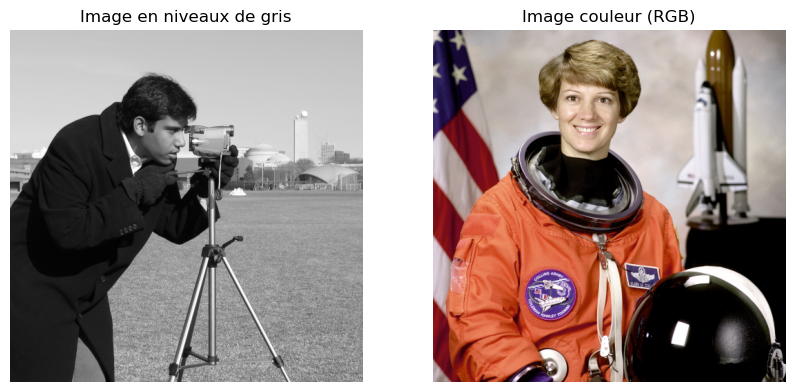

In [3]:
img_gray = data.camera()      # image en niveaux de gris (tableau NumPy 2D)
img_color = data.astronaut()  # image couleur (tableau NumPy 3D, RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_gray, cmap="gray")
axes[0].set_title("Image en niveaux de gris")
axes[0].axis("off")
axes[1].imshow(img_color)
axes[1].set_title("Image couleur (RGB)")
axes[1].axis("off")
plt.show()

> **Charger votre propre image :** avec OpenCV, utilisez `img = cv2.imread("chemin/vers/image.jpg")`.
> ⚠️ OpenCV charge les images en **BGR** (et non RGB) : pensez à convertir avec
> `img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` avant de l'afficher avec Matplotlib, sous peine d'obtenir des couleurs inversées.

## 2. Explorer les propriétés d'une image

Une image chargée est un simple tableau NumPy : elle possède une forme (`shape`), un type de données (`dtype`), et des valeurs min/max.

In [6]:
print("Dimensions (shape)   :", img_gray.shape)
print("Type de données (dtype) :", img_gray.dtype)
print("Valeur minimale         :", img_gray.min())
print("Valeur maximale         :", img_gray.max())
print()
print("Image couleur - dimensions :", img_color.shape, " (hauteur, largeur, canaux)")

Dimensions (shape)   : (512, 512)
Type de données (dtype) : uint8
Valeur minimale         : 0
Valeur maximale         : 255

Image couleur - dimensions : (512, 512, 3)  (hauteur, largeur, canaux)


**À retenir :** pour une image 8 bits, `dtype` vaut `uint8` (entiers non signés de 0 à 255). Une image en niveaux de gris est un tableau 2D ; une image couleur est un tableau 3D (le 3ᵉ axe étant les canaux).

## 3. Indexation et manipulation directe des pixels

Comme pour tout tableau NumPy, on accède à un pixel par `I[ligne, colonne]` (attention à l'ordre : **hauteur puis largeur**, pas x puis y), et on peut modifier des régions entières par *slicing*.

Valeur du pixel (ligne=100, colonne=200) : 54


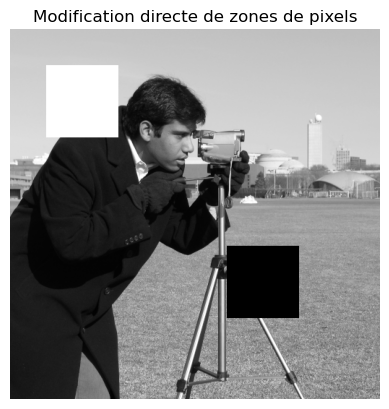

In [7]:
print("Valeur du pixel (ligne=100, colonne=200) :", img_gray[100, 200])

img_modif = img_gray.copy()          # toujours copier avant de modifier !
img_modif[50:150, 50:150] = 255      # carré blanc
img_modif[300:400, 300:400] = 0      # carré noir

plt.imshow(img_modif, cmap="gray")
plt.title("Modification directe de zones de pixels")
plt.axis("off")
plt.show()

## 4. Canaux R, G, B

Une image couleur peut être vue comme trois matrices superposées.

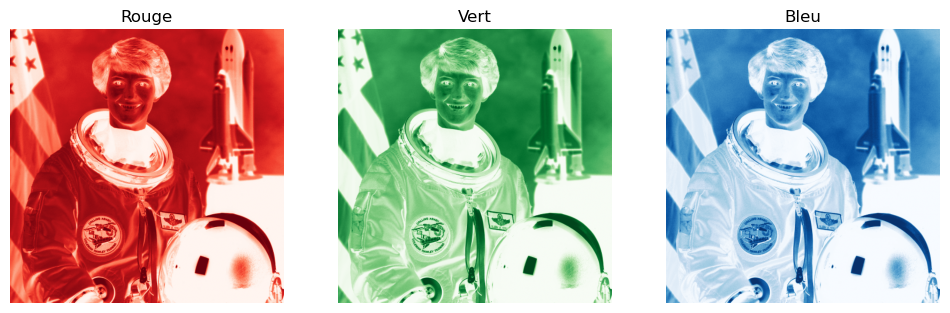

In [8]:
R, G, B = img_color[:, :, 0], img_color[:, :, 1], img_color[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, channel, title, cmap_name in zip(axes, [R, G, B], ["Rouge", "Vert", "Bleu"], ["Reds", "Greens", "Blues"]):
    ax.imshow(channel, cmap=cmap_name)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 5. Conversion en niveaux de gris

On compare une conversion manuelle (formule pondérée vue en cours) et la fonction fournie par OpenCV.

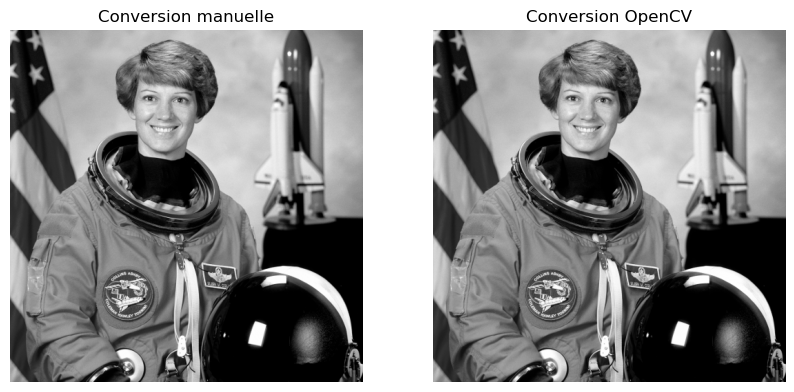

Écart moyen entre les deux méthodes : 0.449


In [9]:
# Méthode 1 : formule manuelle
gray_manual = (0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)

# Méthode 2 : fonction OpenCV
gray_cv2 = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray_manual, cmap="gray"); axes[0].set_title("Conversion manuelle"); axes[0].axis("off")
axes[1].imshow(gray_cv2, cmap="gray"); axes[1].set_title("Conversion OpenCV"); axes[1].axis("off")
plt.show()

ecart = np.abs(gray_manual.astype(int) - gray_cv2.astype(int))
print("Écart moyen entre les deux méthodes :", round(ecart.mean(), 3))

## 6. Statistiques de base

(Ces notions seront approfondies dans le TP1.)

In [10]:
mu = img_gray.mean()
sigma = img_gray.std()
print(f"Moyenne (µ)    : {mu:.2f}")
print(f"Écart-type (σ) : {sigma:.2f}")
print(f"Min / Max      : {img_gray.min()} / {img_gray.max()}")

Moyenne (µ)    : 129.06
Écart-type (σ) : 73.64
Min / Max      : 0 / 255


## 7. Histogramme

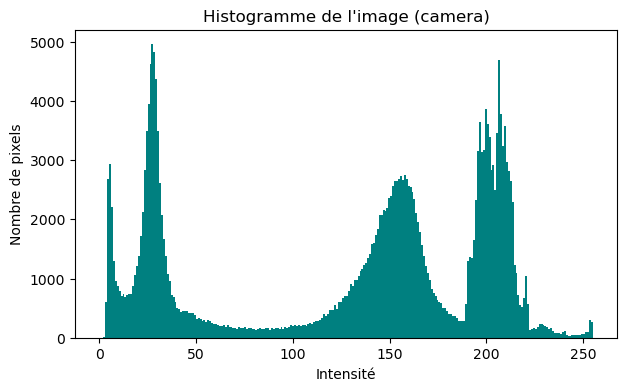

In [11]:
plt.figure(figsize=(7, 4))
plt.hist(img_gray.ravel(), bins=256, range=(0, 255), color="teal")
plt.xlabel("Intensité"); plt.ylabel("Nombre de pixels")
plt.title("Histogramme de l'image (camera)")
plt.show()

Comparons avec une image plus sombre :

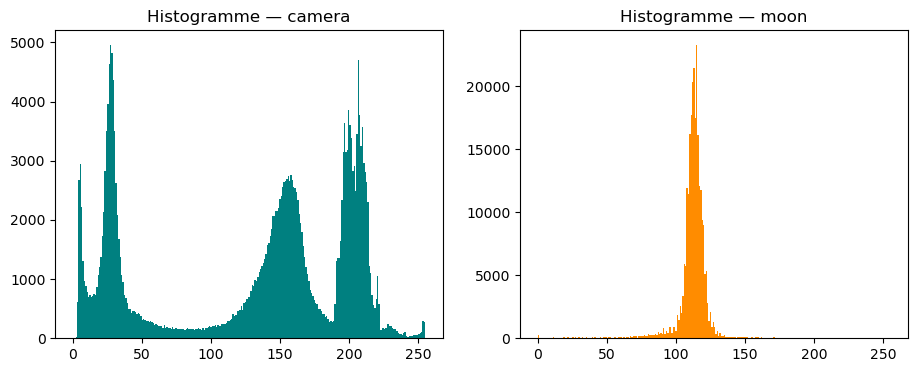

In [12]:
img2 = data.moon()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(img_gray.ravel(), bins=256, range=(0, 255), color="teal")
axes[0].set_title("Histogramme — camera")
axes[1].hist(img2.ravel(), bins=256, range=(0, 255), color="darkorange")
axes[1].set_title("Histogramme — moon")
plt.show()

## 8. Seuillage binaire

Une première forme (très simple) de segmentation : ne garder que deux valeurs possibles.

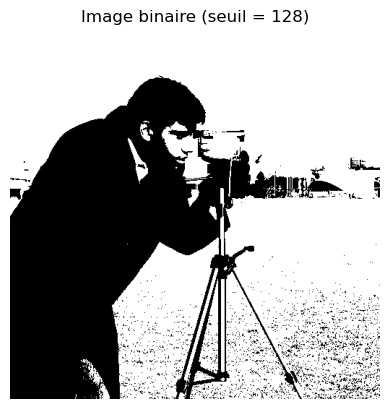

In [13]:
seuil = 128
img_bin = (img_gray > seuil).astype(np.uint8) * 255

plt.imshow(img_bin, cmap="gray")
plt.title(f"Image binaire (seuil = {seuil})")
plt.axis("off")
plt.show()

**À essayer :** changez la valeur de `seuil` (par exemple 60 puis 200) et ré-exécutez la cellule. Que remarquez-vous ?

## 9. Filtre moyenne 3×3

Un premier filtre de lissage, pour observer concrètement l'effet d'une convolution.

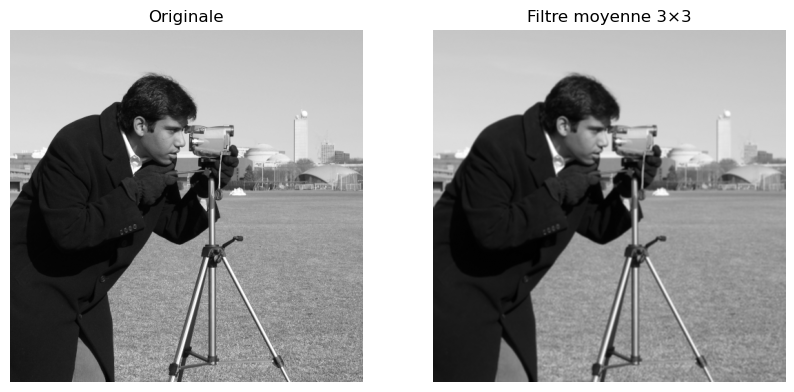

Écart-type avant filtrage : 73.64
Écart-type après filtrage : 72.61


In [14]:
img_flou = cv2.blur(img_gray, (3, 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_gray, cmap="gray"); axes[0].set_title("Originale"); axes[0].axis("off")
axes[1].imshow(img_flou, cmap="gray"); axes[1].set_title("Filtre moyenne 3×3"); axes[1].axis("off")
plt.show()

print("Écart-type avant filtrage :", round(img_gray.std(), 2))
print("Écart-type après filtrage :", round(img_flou.std(), 2))

## 10. À vous de jouer

En utilisant **votre propre image** (`cv2.imread`, ne pas oublier la conversion BGR → RGB) :

1. Affichez l'image et ses dimensions.
2. Calculez sa moyenne et son écart-type.
3. Affichez son histogramme.
4. Testez trois seuils différents et comparez les images binaires obtenues.
5. Appliquez un filtre moyenne 5×5 (`cv2.blur(img, (5,5))`) et comparez-le au filtre 3×3.

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Chargez VOTRE image (remplacez le chemin)
img_bgr = cv2.imread("./images.jpeg")

# Vérification : cv2.imread renvoie None si le fichier n'existe pas
if img_bgr is None:
    raise FileNotFoundError("Image introuvable ! Vérifiez le chemin.")

# Conversion BGR → RGB pour l'affichage avec matplotlib
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Version niveaux de gris (utile pour seuillage, histogramme, filtres)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

Dimensions (hauteur, largeur, canaux) : (678, 452, 3)
Type de données                       : uint8
Niveaux de gris - shape               : (678, 452)


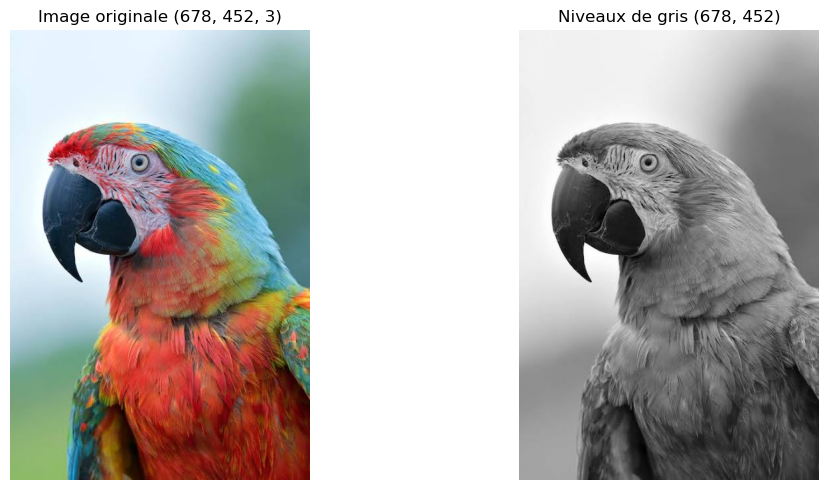

In [23]:
print("Dimensions (hauteur, largeur, canaux) :", img_rgb.shape)
print("Type de données                       :", img_rgb.dtype)
print("Niveaux de gris - shape               :", img_gray.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_rgb)
axes[0].set_title(f"Image originale {img_rgb.shape}")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title(f"Niveaux de gris {img_gray.shape}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [24]:
# Moyenne et écart-type globaux (tous les pixels confondus)
mean_val = np.mean(img_gray)
std_val  = np.std(img_gray)

print(f"Moyenne      : {mean_val:.2f}")
print(f"Écart-type   : {std_val:.2f}")

# Option : moyenne par canal (pour l'image couleur)
mean_rgb = np.mean(img_rgb, axis=(0, 1))
std_rgb  = np.std(img_rgb,  axis=(0, 1))
print(f"Moyenne par canal (R, G, B) : {mean_rgb}")
print(f"Écart-type par canal        : {std_rgb}")

Moyenne      : 141.15
Écart-type   : 65.92
Moyenne par canal (R, G, B) : [151.54334717 138.20258699 128.97426384]
Écart-type par canal        : [60.40558126 75.18432945 84.65971344]


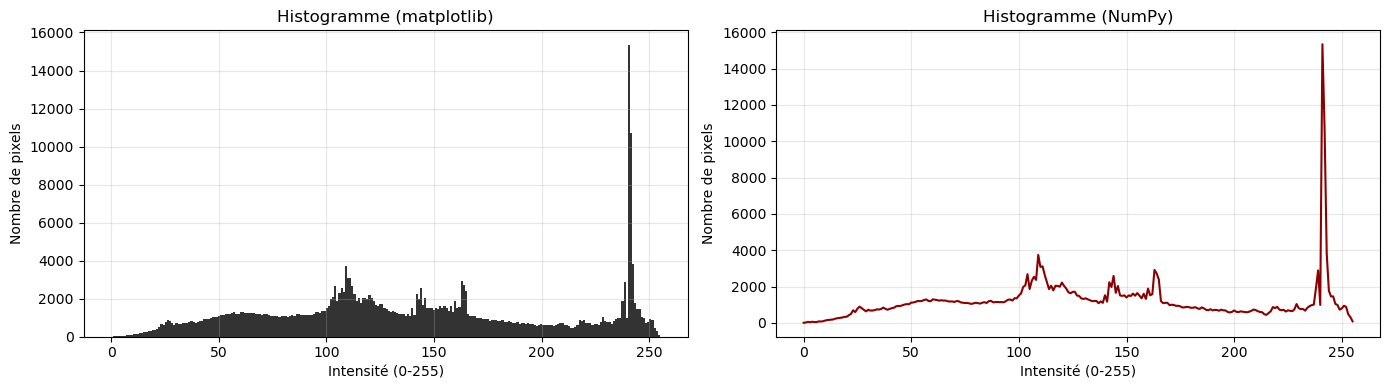

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# (a) Histogramme avec matplotlib (le plus simple)
axes[0].hist(img_gray.ravel(), bins=256, range=(0, 255),
             color="black", alpha=0.8)
axes[0].set_title("Histogramme (matplotlib)")
axes[0].set_xlabel("Intensité (0-255)")
axes[0].set_ylabel("Nombre de pixels")
axes[0].grid(True, alpha=0.3)

# (b) Histogramme avec NumPy (sans matplotlib)
hist = np.histogram(img_gray, bins=256, range=(0, 255))[0]
axes[1].plot(hist, color="darkred")
axes[1].set_title("Histogramme (NumPy)")
axes[1].set_xlabel("Intensité (0-255)")
axes[1].set_ylabel("Nombre de pixels")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Seuil  80 →  79.7% de pixels blancs
Seuil 128 →  52.4% de pixels blancs
Seuil 180 →  28.4% de pixels blancs


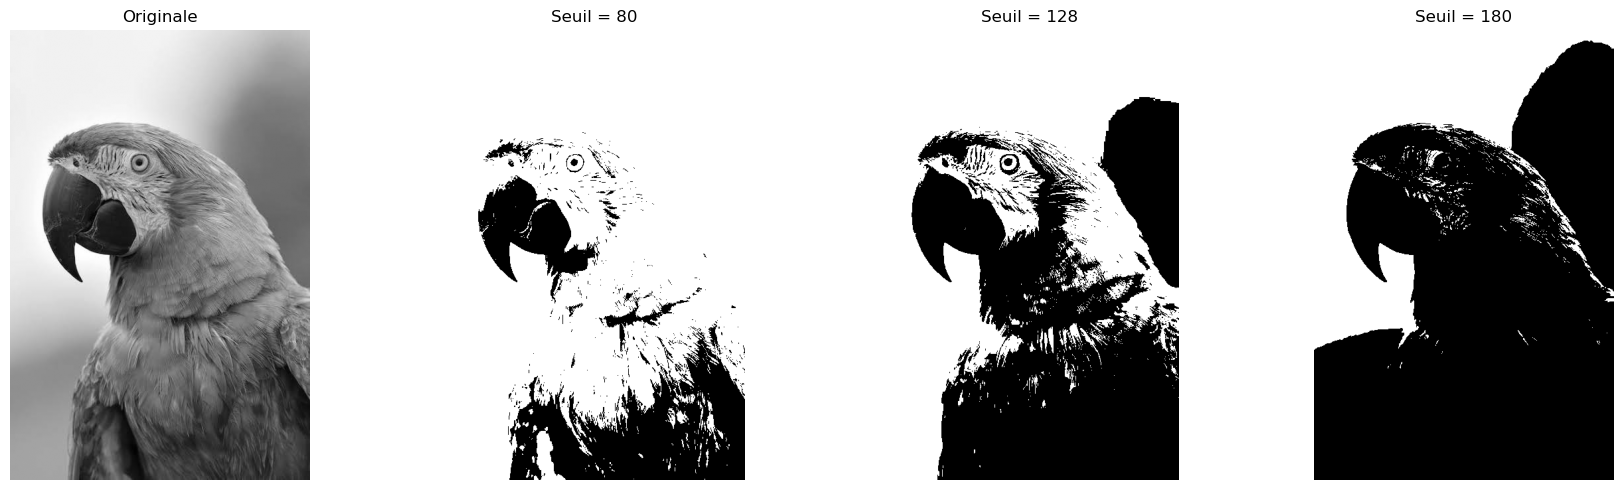

In [26]:
thresholds = [80, 128, 180]
binaries = []

for t in thresholds:
    _, binary = cv2.threshold(img_gray, t, 255, cv2.THRESH_BINARY)
    binaries.append(binary)
    # Pourcentage de pixels blancs
    pct_white = np.sum(binary == 255) / binary.size * 100
    print(f"Seuil {t:3d} → {pct_white:5.1f}% de pixels blancs")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_gray, cmap="gray")
axes[0].set_title("Originale")
axes[0].axis("off")

for ax, t, b in zip(axes[1:], thresholds, binaries):
    ax.imshow(b, cmap="gray")
    ax.set_title(f"Seuil = {t}")
    ax.axis("off")

plt.tight_layout()
plt.show()

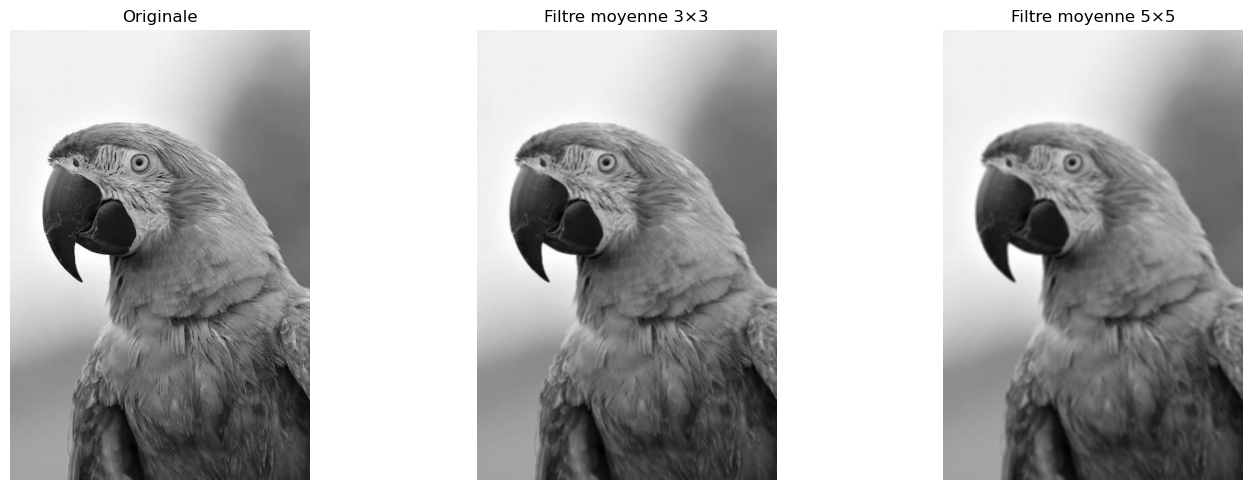

Écart-type original   : 65.92
Écart-type 3×3        : 65.30
Écart-type 5×5        : 64.90


In [27]:
# Filtre moyenne 3×3
blur_3x3 = cv2.blur(img_gray, (3, 3))

# Filtre moyenne 5×5
blur_5x5 = cv2.blur(img_gray, (5, 5))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_gray, cmap="gray")
axes[0].set_title("Originale")
axes[0].axis("off")

axes[1].imshow(blur_3x3, cmap="gray")
axes[1].set_title("Filtre moyenne 3×3")
axes[1].axis("off")

axes[2].imshow(blur_5x5, cmap="gray")
axes[2].set_title("Filtre moyenne 5×5")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Mesure objective du flou : écart-type de l'image (le flou réduit le contraste)
print(f"Écart-type original   : {np.std(img_gray):.2f}")
print(f"Écart-type 3×3        : {np.std(blur_3x3):.2f}")
print(f"Écart-type 5×5        : {np.std(blur_5x5):.2f}")

## Questions de réflexion

- Pourquoi OpenCV charge-t-il les images en BGR plutôt qu'en RGB ?
- Que se passe-t-il si le seuil de binarisation est très proche de 0 ? Très proche de 255 ?
- Pourquoi l'écart-type diminue-t-il après un filtre moyenne ?
- Quelle est la différence fondamentale entre modifier un pixel directement (section 3) et appliquer un filtre (section 9) ?

## Pour aller plus loin

Ce TP0 pose les bases manipulées plus en profondeur dans :
- **TP1** — Calculs numériques : moyenne, variance, histogramme, entropie, MAE/MSE, PSNR, convolution.
- **TP2** — Mesures géométriques : aire, périmètre, centroïde, bounding box, circularité.

# Réponses courtes — Questions de réflexion TP0

## 1. Pourquoi OpenCV charge en BGR et non RGB ?

**Réponse :** Héritage historique. OpenCV (Intel, années 2000) s'est aligné sur les pilotes caméras et le format BMP qui utilisaient BGR. Ce choix a été figé dans l'API pour préserver la compatibilité ascendante. RGB s'est imposé plus tard comme standard web/scientifique (Matplotlib, PIL).

**Conséquence :** toujours convertir avec :

```python
cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
```

avant affichage.

---

## 2. Seuil très proche de 0 ? Très proche de 255 ?

* **T ≈ 0** → presque tous les pixels > T → image **blanche** (saturée).
* **T ≈ 255** → presque aucun pixel > T → image **noire** (vide).

Dans les deux cas : **perte totale d'information**. Le bon seuil se trouve dans le creux de l'histogramme (souvent donné par la méthode d'**Otsu**).

---

## 3. Pourquoi l'écart-type diminue après un filtre moyenne ?

Le filtre moyenne est un **passe-bas** : il atténue les hautes fréquences (bruit, contours).

Statistiquement, pour un noyau `k × k` :

$$
\sigma_{\text{out}} = \frac{\sigma_{\text{in}}}{k}
$$

Donc :

* **3×3** réduit σ d'un facteur 3.
* **5×5** réduit σ d'un facteur 5.

**Conséquence visuelle :** image plus lisse et moins contrastée.

---

## 4. Différence pixel direct vs filtre ?

Modifier un pixel = écrire une valeur ponctuelle, sans regarder le voisinage → **édition locale**.

Appliquer un filtre = calculer chaque pixel à partir de tout son voisinage (convolution) → **traitement global**.

**En une phrase :** modifier un pixel, c'est **imposer** ; filtrer, c'est **calculer en contexte**.

---

# Synthèse

| №     | Réponse en une ligne                                                          |
| ----- | ----------------------------------------------------------------------------- |
| **1** | BGR = héritage historique Intel/Windows, gardé pour compatibilité.            |
| **2** | T≈0 → tout blanc ; T≈255 → tout noir ; dans les deux cas, information perdue. |
| **3** | Filtre = passe-bas → hautes fréquences atténuées → σ diminue (σ/k).           |
| **4** | Pixel = écriture locale aveugle ; filtre = convolution globale contextuelle.  |
